## ISOM4030 Lab 7 - Convolutional Neural Network (CNN)

### Overview
In Lab 7.1, we built and trained a basic neural network model to classify images from the MNIST database of handwritten digits. The model achieved an accuracy of approximately 92.3%, which is a solid result. In this section, we’ll take things a step further by introducing a more powerful type of neural network known as a convolutional neural network (CNN) — a model particularly well-suited for interpreting and classifying image data.


### Setup

In [4]:
# Set up the programming environment

# import data munging libraries

import pandas as pd
import numpy as np

# import drawing libraries and configure drawing settings

import matplotlib.pyplot as plt

%config InlineBackend.figure_format="retina"

# import several utility functions
# Upload lab_utils.py to Google Colab

from lab_utils import visualize_feature_maps, file_tree, visualize_raw_images

# import tensorflow and keras API

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, Sequential


# Convolutional Neural Network


We will build the following model to detect hand-written digits (MNIST):

```Python
                    Input
                      ↧
       [Rescaling(scale factor 1./255)]
                      ↧          
[Conv2D(32 3x3 filters, stride of 1, no padding)]
                      ↧
           [BatchNormalization()]
                      ↧
                   [ReLU()]
                      ↧
   [MaxPooling2D(2x2 filter, a stride of 2)]
                      ↧
[Conv2D(32 3x3 filters, stride of 1, no padding)]
                      ↧
           [BatchNormalization()]
                      ↧
                   [ReLU()]
                      ↧
   [MaxPooling2D(2x2 filter, a stride of 2)]
                      ↧
                 [Flatten()]
                      ↧
     [Dense(128 units, relu activation)]
                      ↧
         [Dropout(dropout rate 0.2)]
                      ↧
    [Dense(10 units, softmax activation)]
                      ↧
                   Output
```




<br>

---




## 1. Convolutional Layers

In a Conv2D layer (2D convolution), the model is performing a mathematical operation that helps it detect patterns in images—like edges, textures, and shapes. The Conv2D layer applies filters (kernels) to the input image.

Each filter is a small matrix (e.g., 3×3) that slides over the image and performs element-wise multiplication and summation. Filters start with random values. During training, they are updated to detect useful patterns in the input data.

In Keras, the convolutional layer is implemented as `layers.Conv2D` (`2D` in the name indicates that it aims to process 2-dimensional images).

```python
layers.Conv2D(filters, kernel_size, strides=(1, 1), padding='valid', activation=None, ...)
```

Hyperparameters:

- Number of filters (`filters`)
- Dimension of filters (`kernel_size`)
- Padding (`padding`).
    - `"valid"` means no padding.
    - `"same"` means auto-padding.   
- Stride (`strides`)
    - Default is `(1,1)`


In [5]:
# Define a convolutional layer with 32 filters, each 3 × 3, using a stride of 1, and no padding


layers.Conv2D(filters=32, kernel_size=3, strides=(1, 1), padding='valid')


<Conv2D name=conv2d, built=False>

## 2. Pooling Layers

The pooling layers shrinks the width and height of the feature maps, and reduces the number of computations and memory usage in later layers. It keeps the most activated regions, which are likely to be more meaningful. Also, it reduces sensitivity to small shifts, helping CNNs recognize patterns even if the object moves slightly in the image.


In Keras, the pooling layer is implemented as `layers.MaxPooling2D` or `layers.AveragePooling2D` .  

```python
layers.MaxPooling2D(pool_size=(2, 2), strides=None, ...)
layers.AveragePooling2D(pool_size=(2, 2), strides=None, ...)
```


In [6]:
# Define a MaxPooling layer to squeeze every 4 pixels into 1, no padding
# so as to reduce the image to 25% of the original size


layers.MaxPooling2D(pool_size=(2, 2), strides=2)


<MaxPooling2D name=max_pooling2d, built=True>


---


##3. Build and Train the CNN Model


Load the MNIST dataset and explore the data a bit:

In [7]:
# Load the MNIST dataset and standardize the data

(X_train, y_train), (X_validation, y_validation) = keras.datasets.mnist.load_data()

# Explore the data

print("The shape of training features:", X_train.shape)
print("The shape of training labels:", y_train.shape)
print("The shape of validation features:", X_validation.shape)
print("The shape of validation labels:", y_validation.shape)

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
The shape of training features: (60000, 28, 28)
The shape of training labels: (60000,)
The shape of validation features: (10000, 28, 28)
The shape of validation labels: (10000,)




We're going to bulid the model with the `Sequential` model constructor as usual. Then compile it with the `Adam` optimization algorithm and the `SparseCategoricalCrossentropy` loss function. Train the model with 3 epochs:


In [8]:
# Set a random seed to make the results reproducible
np.random.seed(1)
tf.random.set_seed(1)

# Build the model (Define the layers and stack them into a network in order)

model = Sequential([
  # include feature scaling as part of the model
  # 28x28 examples implicitly converted to a shape of 28x28x1
  # becasue the subsequent conv2d layer expects each example to have 3 dimensions
  layers.Rescaling(scale=1./255, input_shape=(28, 28, 1)),

  # add convolution
  layers.Conv2D(32, (3, 3), name="conv_1"),
  # add batch normalization to make the model converge faster on the training data
  layers.BatchNormalization(name="batch_1"),
  # add non-linearity
  layers.ReLU(name="relu_1"),
  # add max pooling
  layers.MaxPooling2D((2, 2), (2, 2), name="pool_1"),

  # repeat the above combination one more time
  layers.Conv2D(32, (3, 3), name="conv_2"),
  layers.BatchNormalization(name="batch_2"),
  layers.ReLU(name="relu_2"),
  layers.MaxPooling2D((2, 2), (2, 2), name="pool_2"),

  # flatten the results to feed into a feedforward network
  layers.Flatten(name="flatten"),
  # 128 neuron hidden layer
  layers.Dense(128, activation='relu', name="fully-connected"),
  # 1 dropout layer to combat overfitting
  layers.Dropout(rate=0.2, name="dropout"),
  # 10 output neurons because we have 10 classes (i.e., 0-9 10 digits)
  layers.Dense(10, activation='softmax', name="output")])


# Print the model summary

model.summary()

# Compile the model

model.compile(optimizer=keras.optimizers.Adam(),
              loss=keras.losses.SparseCategoricalCrossentropy(),
              metrics=['accuracy'])

# Train the model

print('\nMODEL TRAINING:')
model_output = model.fit(X_train, y_train, epochs=3, validation_data=[X_validation, y_validation])


/usr/local/lib/python3.13/dist-packages/keras/src/layers/preprocessing/data_layer.py:95: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling (Rescaling)           │ (None, 28, 28, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_1 (Conv2D)                 │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_1 (BatchNormalization)    │ (None, 26, 26, 32)     │           128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ relu_1 (ReLU)                   │ (None, 26, 26, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool_1 (MaxPooling2D)           │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_2 (Conv2D)                 │ (None, 11, 11, 32)     │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_2 (BatchNormalization)    │ (None, 11, 11, 32)     │           128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ relu_2 (ReLU)                   │ (None, 11, 11, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool_2 (MaxPooling2D)           │ (None, 5, 5, 32)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 800)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ fully-connected (Dense)         │ (None, 128)            │       102,528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ output (Dense)                  │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 113,642 (443.91 KB)

 Trainable params: 113,514 (443.41 KB)

 Non-trainable params: 128 (512.00 B)


MODEL TRAINING:
Epoch 1/3
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 17s 5ms/step - accuracy: 0.9576 - loss: 0.1396 - val_accuracy: 0.9817 - val_loss: 0.0554
Epoch 2/3
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.9832 - loss: 0.0564 - val_accuracy: 0.9833 - val_loss: 0.0511
Epoch 3/3
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.9872 - loss: 0.0423 - val_accuracy: 0.9909 - val_loss: 0.0284


It took longer to run each epoch. But it attains >98% validation accuracy with just 2 epoch.

In [9]:
model.evaluate(X_train, y_train)

1875/1875 ━━━━━━━━━━━━━━━━━━━━ 5s 2ms/step - accuracy: 0.9933 - loss: 0.0205


[0.020515667274594307, 0.993316650390625]

---



##4. Visualizing the Convolutions and Pooling


Let's explore how to show the convolutions graphically.

You can pick a random image (e.g., the 1st image) from the training set, and then generate a figure where each row is the output of a layer, and each image in the row is a specific filter in that output.

Feel free to rerun the following cell to generate intermediate feature maps for a variety of training images.


1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step


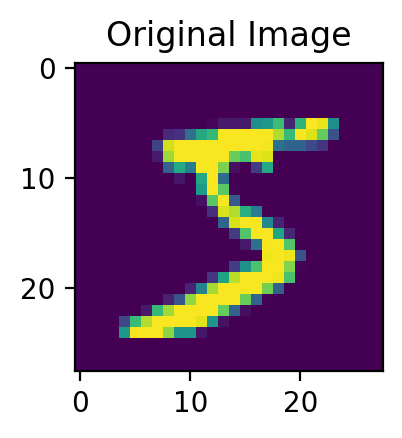

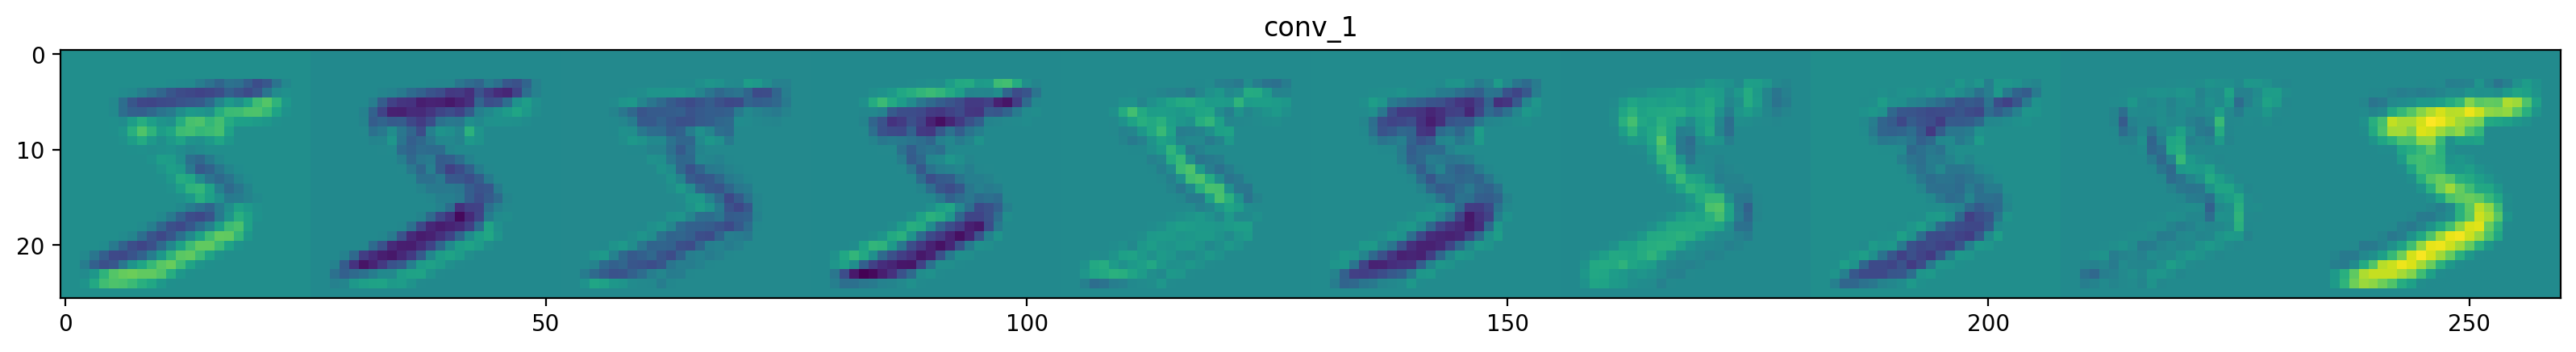

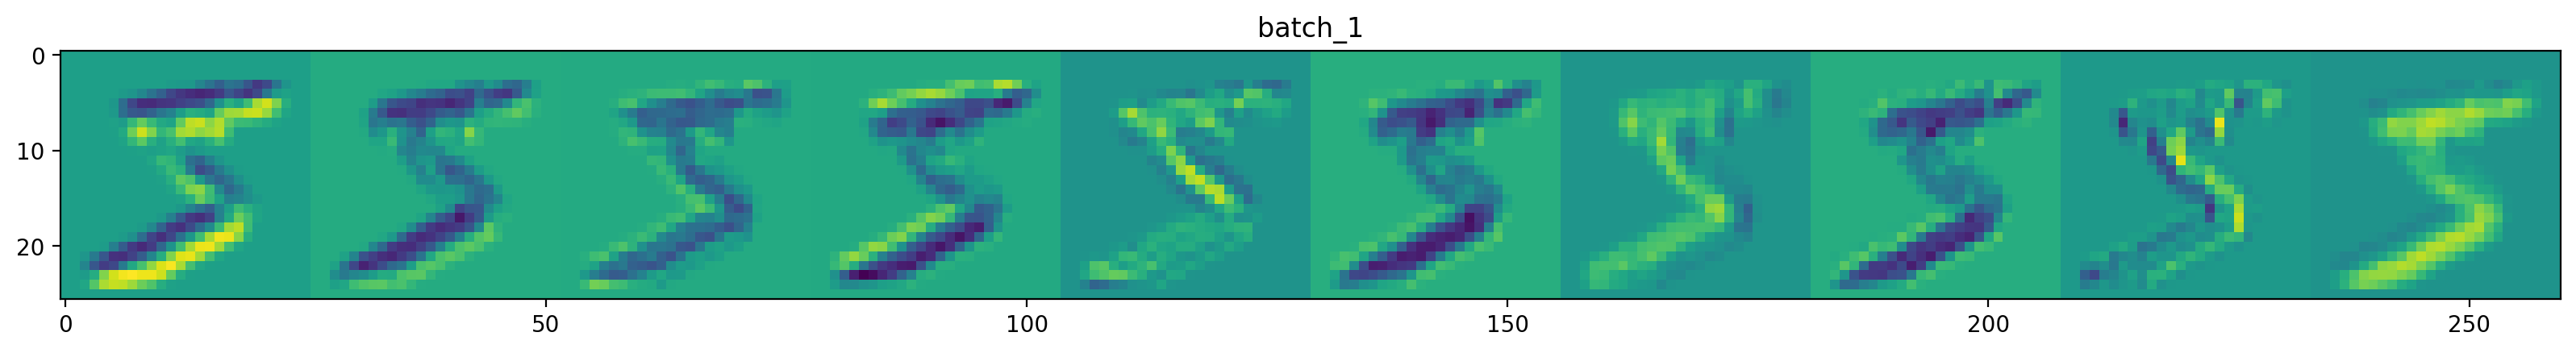

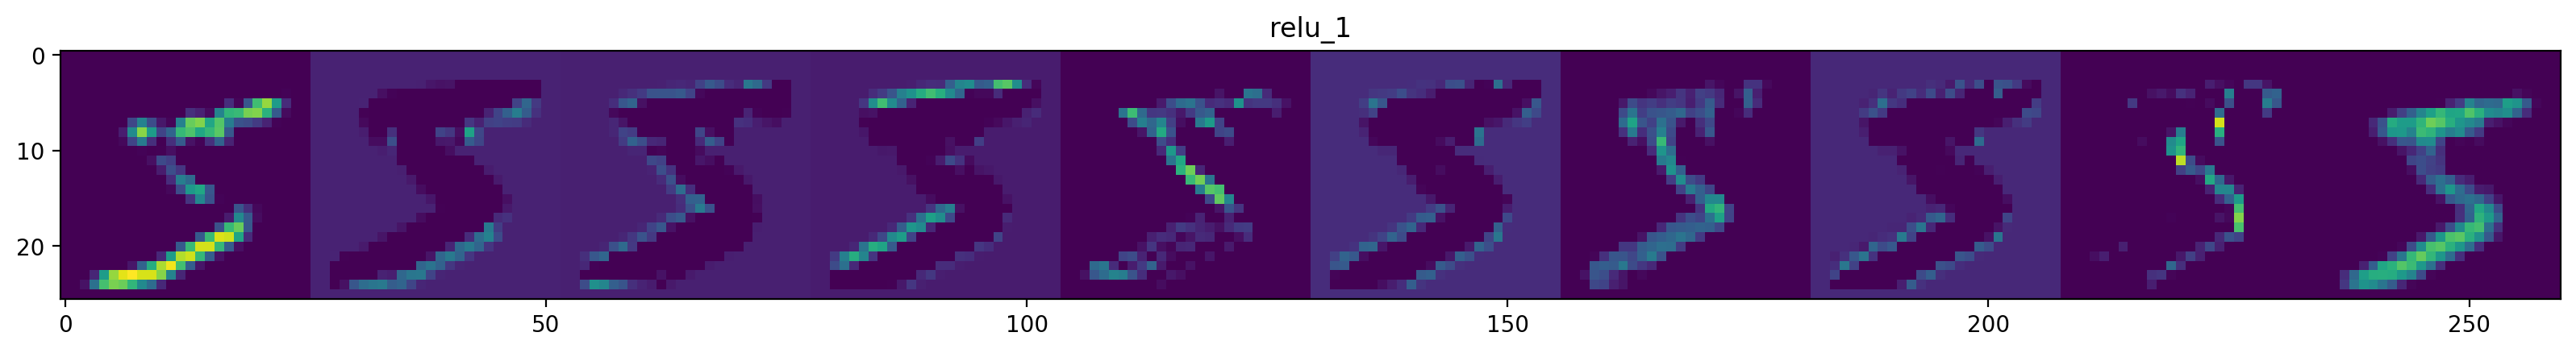

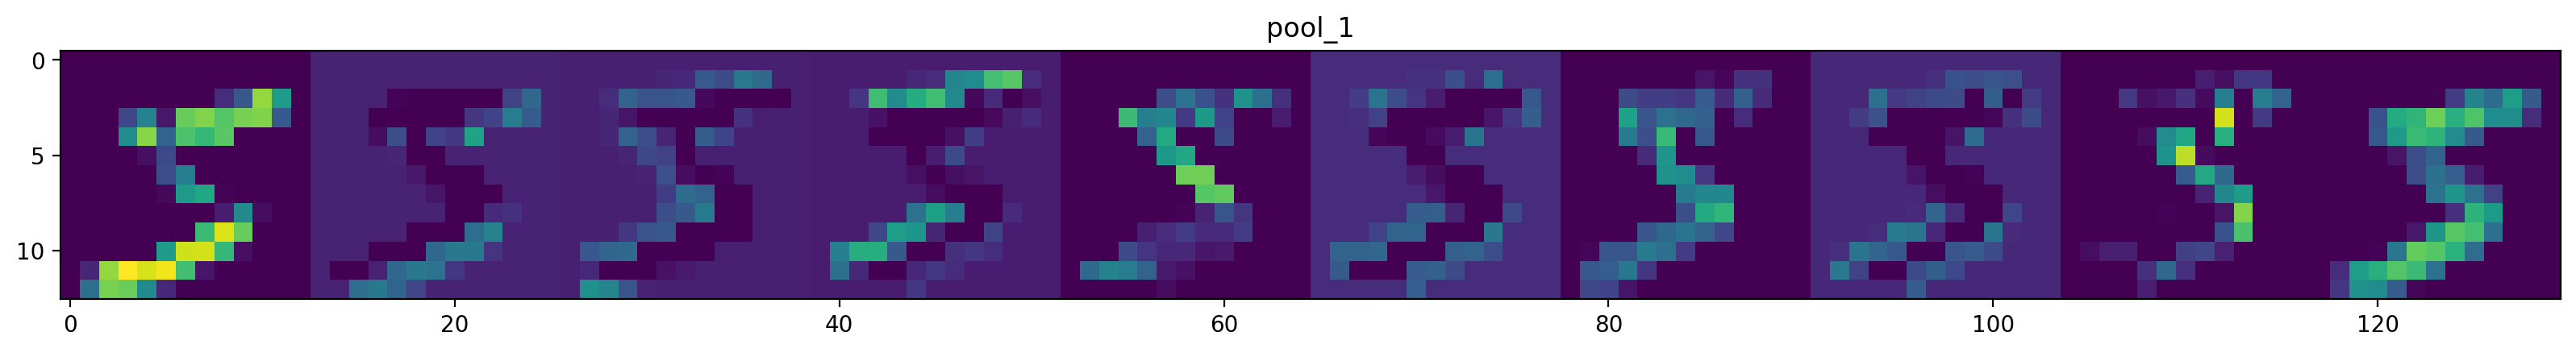

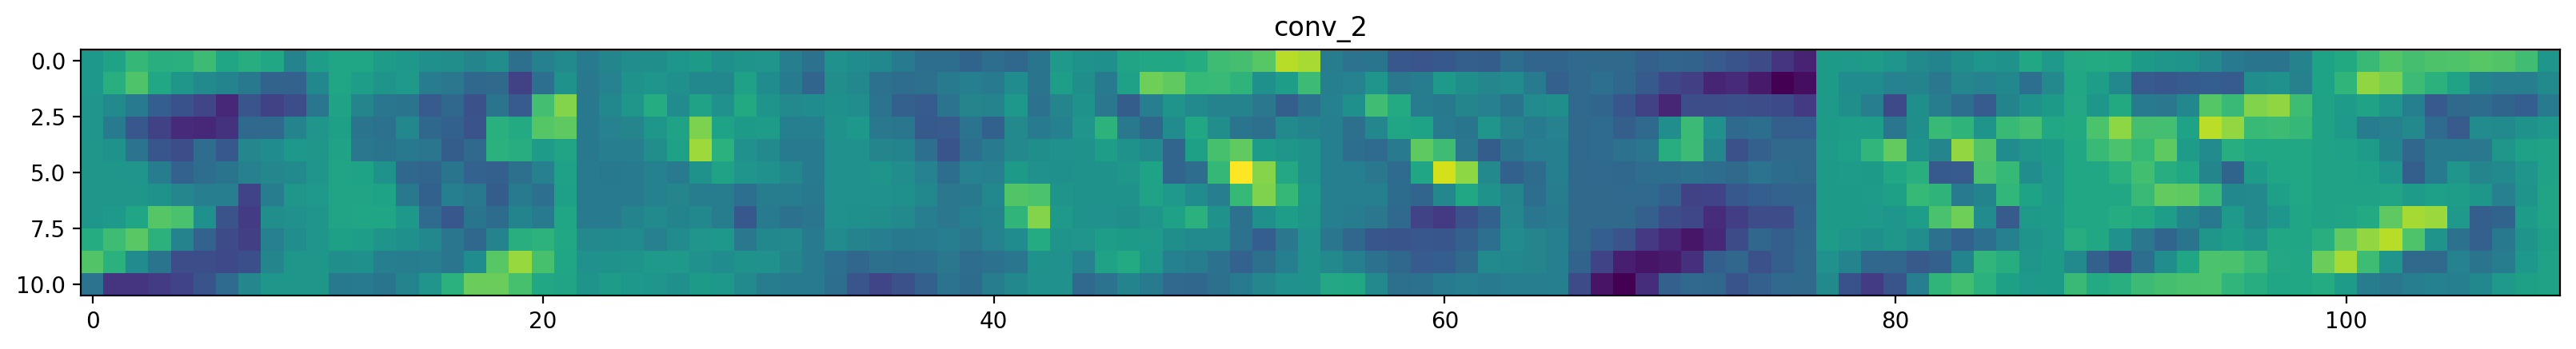

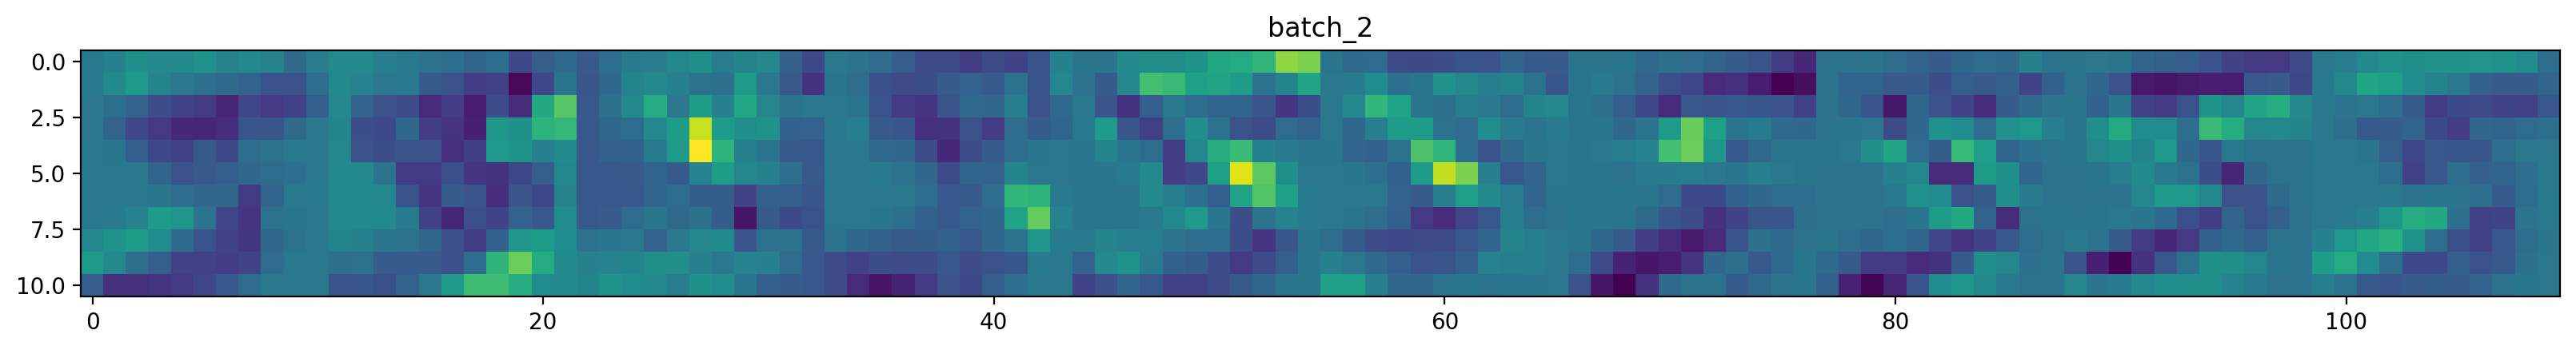

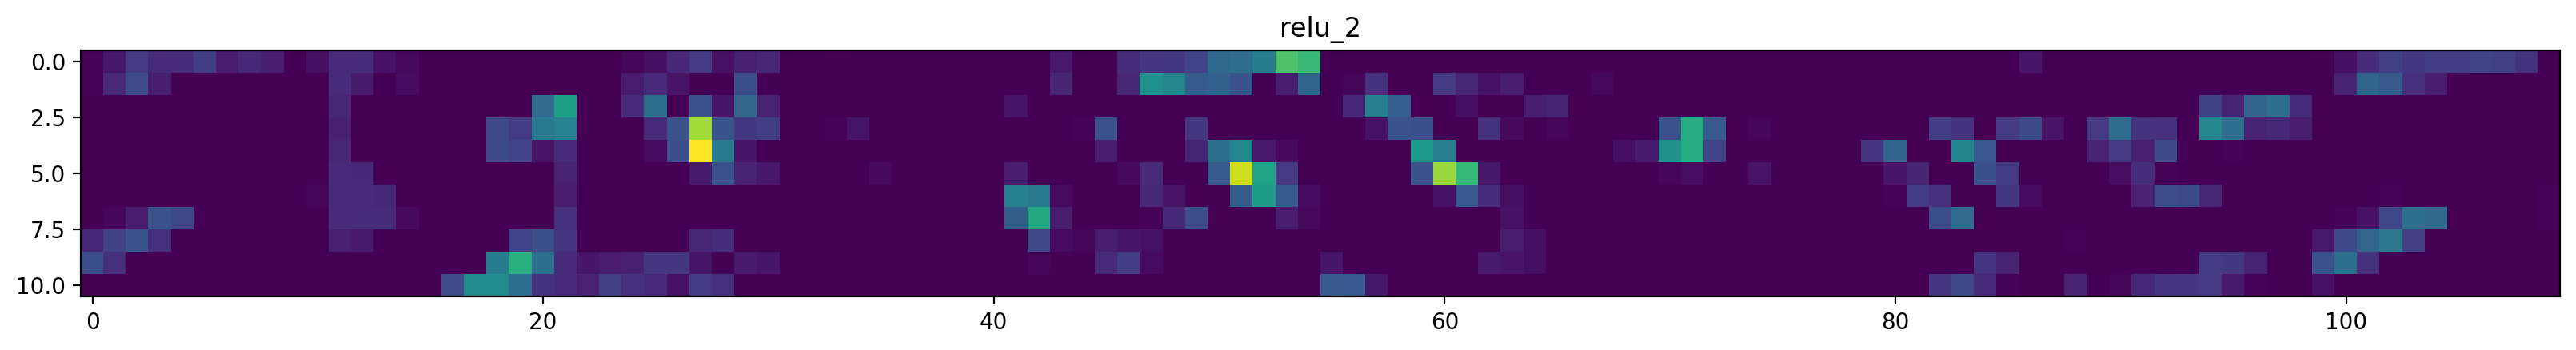

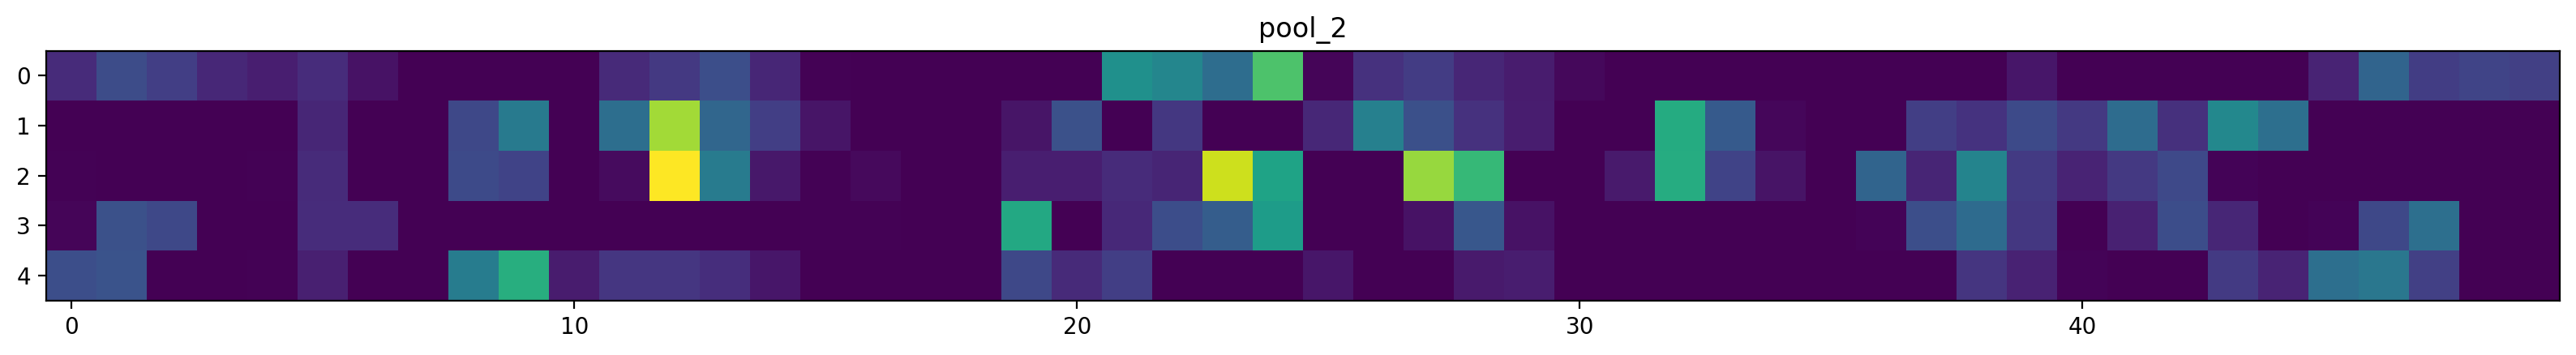

In [10]:
index = 0                                                 # You can replace 0 with 11, 35, 47, etc and rerun it.
plt.figure(figsize=(2, 2))
plt.imshow(X_train[index])
plt.title("Original Image")
visualize_feature_maps(model, data=X_train, indices=[index],
                       image_dim=(28, 28, 1),
                        # layer_indices starts from 1 to exclude the resaling layer
                       layer_indices=range(1, 9))

What we can see from above is how the pixels highlighted become increasingly abstract and compact, especially at the bottom grid.

---


## Group Exercise: Cat vs. Dog?!

Next, we're going to build a model to classify real images of cats and dogs.

Real-world images come in different shapes, aspect ratios, etc. We will need to take this into account when preparing the data.


## Step 1: Explore Data Organization



In [25]:
# Download and extract a zip file containing the images
! gdown -q "https://drive.google.com/uc?id=1ni33VQN65v4bbSfN-syG9D4jLZxHWWjK"

#! wget -q "https://storage.googleapis.com/mledu-datasets/cats_and_dogs_filtered.zip"
! unzip -qq cats_and_dogs.zip
#! mv cats_and_dogs_filtered cats_and_dogs

replace cats_and_dogs/train/cats/cat.0.jpg? [y]es, [n]o, [A]ll, [N]one, [r]ename: A


In [26]:
file_tree('./cats_and_dogs', level=2)

cats_and_dogs
├── train
│   ├── cats
│   └── dogs
└── validation
    ├── cats
    └── dogs

6 directories


In [27]:
file_tree('./cats_and_dogs', length_limit=20)

cats_and_dogs
├── train
│   ├── cats
│   │   ├── cat.359.jpg
│   │   ├── cat.768.jpg
│   │   ├── cat.191.jpg
│   │   ├── cat.832.jpg
│   │   ├── cat.640.jpg
│   │   ├── cat.989.jpg
│   │   ├── cat.668.jpg
│   │   ├── cat.686.jpg
│   │   ├── cat.771.jpg
│   │   ├── cat.263.jpg
│   │   ├── cat.997.jpg
│   │   ├── cat.348.jpg
│   │   ├── cat.55.jpg
│   │   ├── cat.765.jpg
│   │   ├── cat.900.jpg
│   │   ├── cat.725.jpg
│   │   ├── cat.713.jpg
│   │   ├── cat.21.jpg
... length_limit, 20, reached, counted:

2 directories, 18 files


As you can see, the image data has been organized into two folders, one for training and one for validation. Under each folder, there are also subfolders each corresponding to one class label in data.

Let's explore a bit how cat images and dog images look like in this dataset:


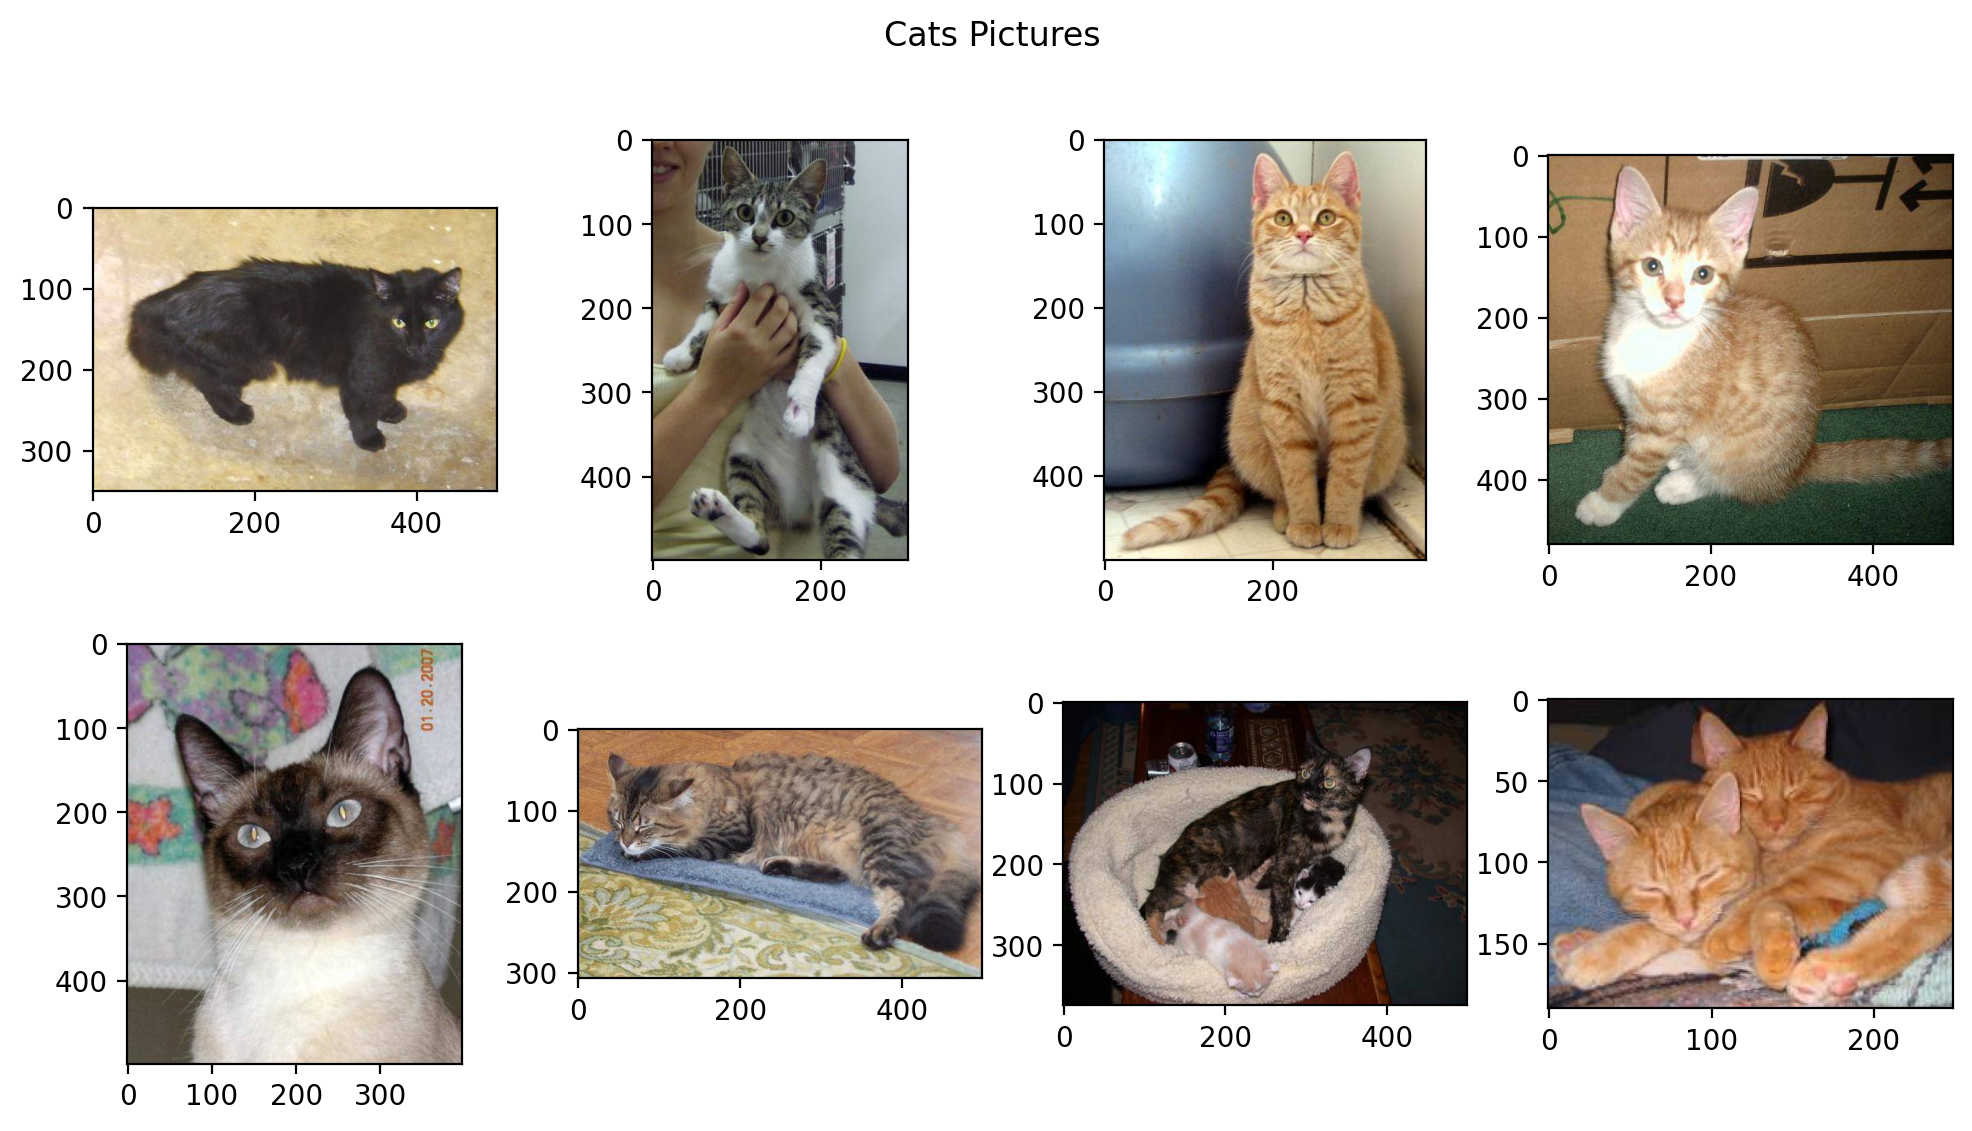

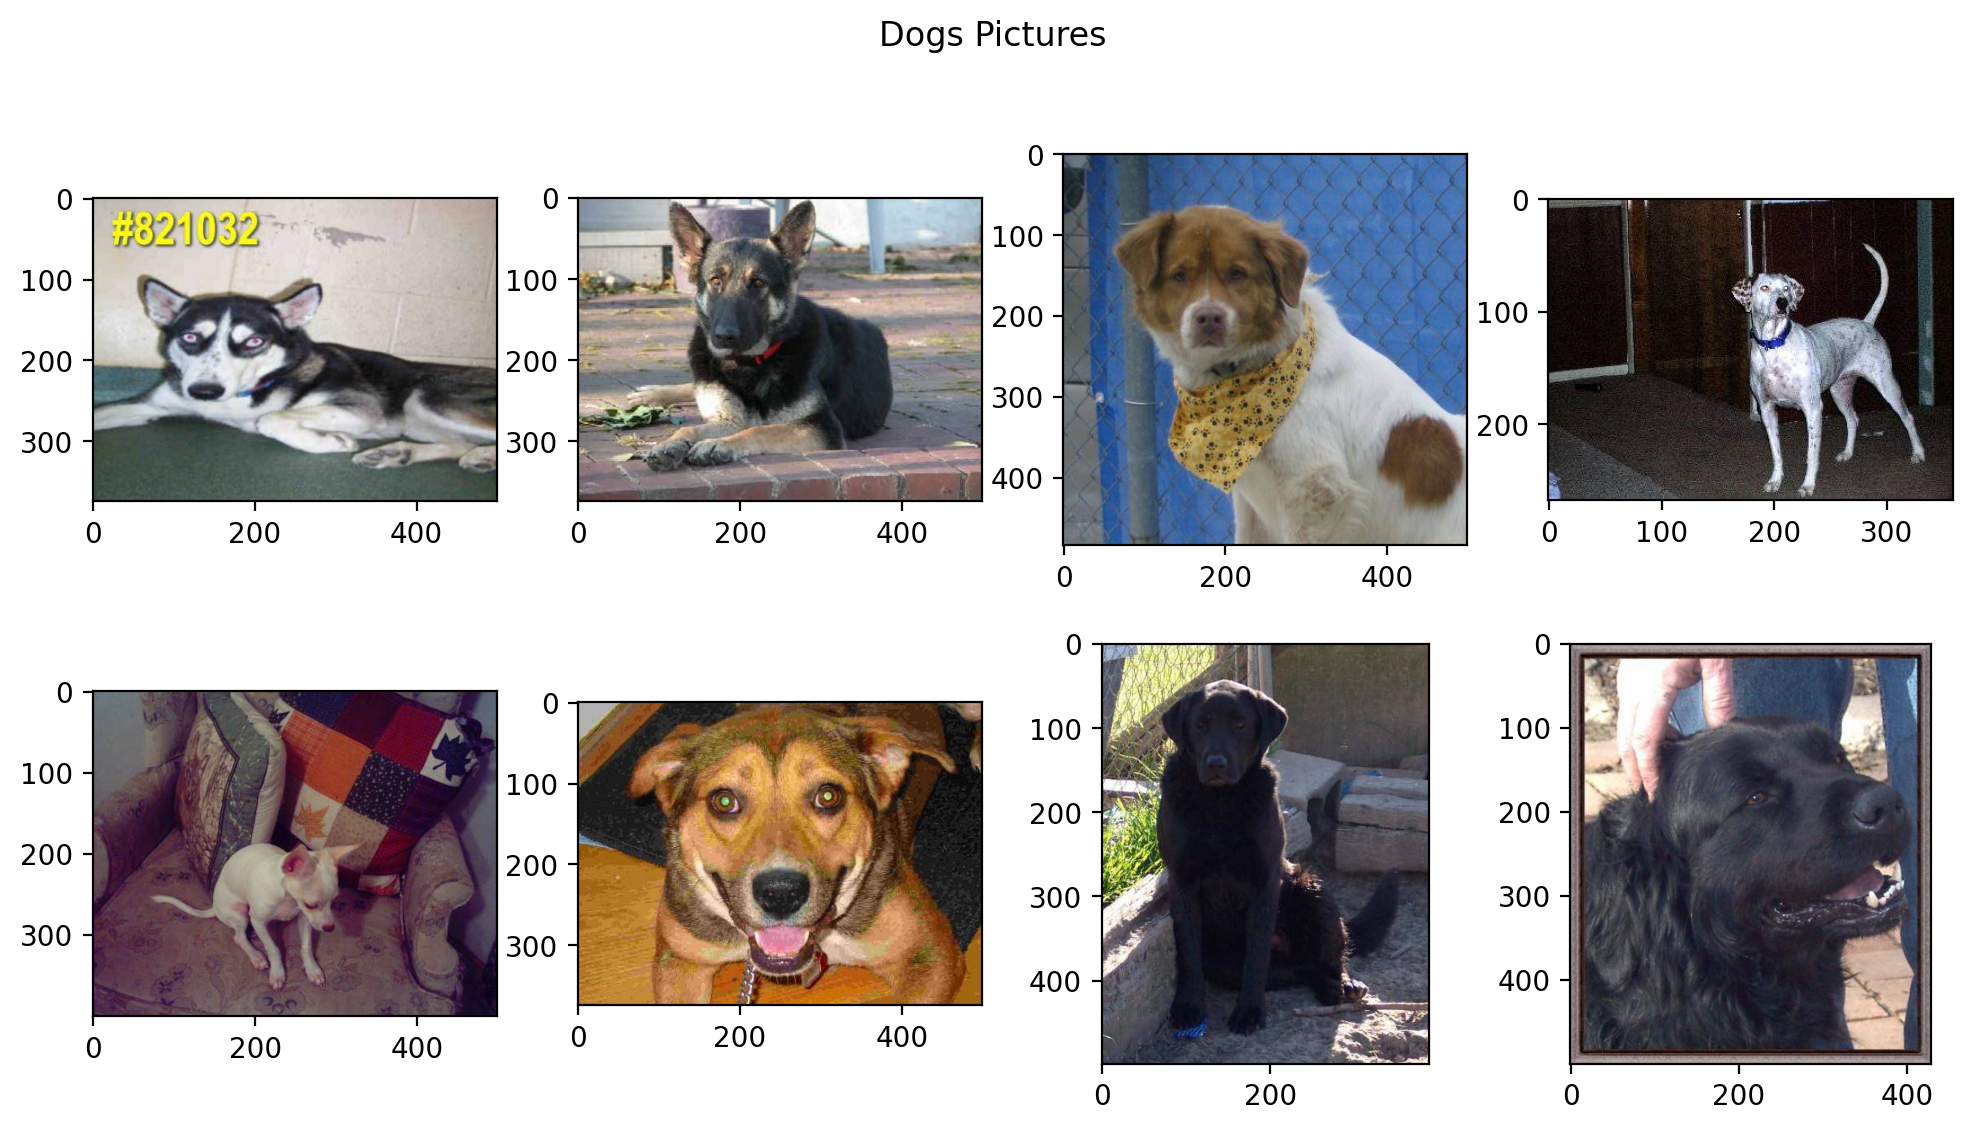

In [28]:
visualize_raw_images("./cats_and_dogs/train")

##Step 2: Data Preprocessing

Next, use the `keras.utils.image_dataset_from_directory` utility to create two data "pumps", which will later stream batched data off disk during training and validation, respectively:

In [29]:
BATCH_SIZE = 32

train_dataset = keras.utils.image_dataset_from_directory('./cats_and_dogs/train',           # This is the source folder for training images
                                                         batch_size=BATCH_SIZE,             # Previously, the batch size is set with model.fit(), but now we are moving it here!
                                                         image_size=(160, 160))             # All images will be resized to 160x160


validation_dataset = keras.utils.image_dataset_from_directory('./cats_and_dogs/validation', # This is the source folder for validation images
                                                              batch_size=BATCH_SIZE,
                                                              image_size=(160, 160))


class_names = train_dataset.class_names
print('\nclass labels inferred from the directory structure:', class_names)
print(f"So, '{class_names[0]}' is encoded as 0, and '{class_names[1]}' is encoded as 1" )

Found 2000 files belonging to 2 classes.
Found 1000 files belonging to 2 classes.

class labels inferred from the directory structure: ['cats', 'dogs']
So, 'cats' is encoded as 0, and 'dogs' is encoded as 1


**Refresher:** A **batch** is a group of samples processed together during training. Instead of updating weights after every single image, the model updates after seeing a batch of images.

We can opt for data prefetching so that when the data is loaded on-the-fly during training and validation, we can buffer the data used for step $s+1$ while the model is still training at step $s$:

In [30]:
AUTOTUNE = tf.data.AUTOTUNE

train_dataset = train_dataset.prefetch(buffer_size=AUTOTUNE)
validation_dataset = validation_dataset.prefetch(buffer_size=AUTOTUNE)

## <font color ='red'> Try it out in Steps 3 - 5!

## Step 3: Build the CNN model

You can copy and paste the previous model, and try it!!

<font color='red'>Tips:</font>

1. Set `input_shape` to `(160, 160, 3)` to fit the current data.
2. This is a binary classification, so you need to adjust the output layer accordingly.


In [31]:
# Fix a random seed to be able to replicate the results

np.random.seed(1)
tf.random.set_seed(1)


# Build and train a CNN model


model = Sequential([

  layers.Rescaling(scale=1./255, input_shape=(160, 160, 3)),

  layers.Conv2D(32, (3, 3), name="conv_1"),
  layers.BatchNormalization(name="batch_1"),
  layers.ReLU(name="relu_1"),
  layers.MaxPooling2D((2, 2), (2, 2), name="pool_1"),

  layers.Conv2D(32, (3, 3), name="conv_2"),
  layers.BatchNormalization(name="batch_2"),
  layers.ReLU(name="relu_2"),
  layers.MaxPooling2D((2, 2), (2, 2), name="pool_2"),

  layers.Flatten(name="flatten"),
  layers.Dense(128, activation='relu', name="fully-connected"),
  layers.Dropout(rate=0.2, name="dropout"),
  layers.Dense(1, activation='sigmoid', name="output")])



# Print the model summary

model.summary()


# Complie and train the model

model.compile(optimizer=keras.optimizers.Adam(),
              loss='binary_crossentropy',
              metrics = ['accuracy'])


# now we use the two data "pumps" for training and validation
model_output = model.fit(train_dataset, epochs=5, validation_data=validation_dataset)

/usr/local/lib/python3.13/dist-packages/keras/src/layers/preprocessing/data_layer.py:95: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling_1 (Rescaling)         │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_1 (Conv2D)                 │ (None, 158, 158, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_1 (BatchNormalization)    │ (None, 158, 158, 32)   │           128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ relu_1 (ReLU)                   │ (None, 158, 158, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool_1 (MaxPooling2D)           │ (None, 79, 79, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_2 (Conv2D)                 │ (None, 77, 77, 32)     │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_2 (BatchNormalization)    │ (None, 77, 77, 32)     │           128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ relu_2 (ReLU)                   │ (None, 77, 77, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool_2 (MaxPooling2D)           │ (None, 38, 38, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 46208)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ fully-connected (Dense)         │ (None, 128)            │     5,914,752 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ output (Dense)                  │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 5,925,281 (22.60 MB)

 Trainable params: 5,925,153 (22.60 MB)

 Non-trainable params: 128 (512.00 B)

Epoch 1/5
63/63 ━━━━━━━━━━━━━━━━━━━━ 17s 147ms/step - accuracy: 0.4810 - loss: 3.3817 - val_accuracy: 0.4900 - val_loss: 0.6936
Epoch 2/5
63/63 ━━━━━━━━━━━━━━━━━━━━ 3s 41ms/step - accuracy: 0.5870 - loss: 0.6713 - val_accuracy: 0.5020 - val_loss: 0.6931
Epoch 3/5
63/63 ━━━━━━━━━━━━━━━━━━━━ 6s 48ms/step - accuracy: 0.5920 - loss: 0.6580 - val_accuracy: 0.5000 - val_loss: 0.6932
Epoch 4/5
63/63 ━━━━━━━━━━━━━━━━━━━━ 3s 40ms/step - accuracy: 0.6080 - loss: 0.6513 - val_accuracy: 0.5150 - val_loss: 0.6924
Epoch 5/5
63/63 ━━━━━━━━━━━━━━━━━━━━ 3s 41ms/step - accuracy: 0.6155 - loss: 0.6434 - val_accuracy: 0.5010 - val_loss: 0.6935


## Step 4: Find an image and try to predict!

Now take a look at actually running a prediction using the model. This code will allow you to choose 1 or more files from your file system, upload them, and run them through the model, giving an indication of whether the object is a cat or a dog.

Some interesting images to try (right-click to save):



<img src="https://media.nature.com/lw800/magazine-assets/d41586-020-01430-5/d41586-020-01430-5_17977552.jpg" width=400/>

<img src="https://static.onecms.io/wp-content/uploads/sites/20/2022/02/17/Dogs-Catching-Cheese-02.jpg" width=400/>

<img src="https://scx2.b-cdn.net/gfx/news/2022/dogs-exhibit-behaviors.jpg" width=400/>

<img src="https://d3544la1u8djza.cloudfront.net/APHI/Blog/2020/05-14/How+Do+Dogs+Get+Hernias+_+ASPCA+Pet+Insurance+_+shiba+inu+with+an+orange+collar+resting+on+a+tan+chair-min.jpg" width=400/>

<img src="https://sp-ao.shortpixel.ai/client/to_auto,q_lossless,ret_img,w_940,h_640/https://moderncat.com/wp-content/uploads/2014/03/tortoiseshell-kitten-closeup-p-46771525-940x640.jpg" width=400/>

<img src="https://cdn.mos.cms.futurecdn.net/KYEJp9vem3QQFGhi25SYx4-1200-80.jpg" width=400/>

 <img src="https://d.newsweek.com/en/full/1930810/cat.jpg" width=400/>

 <img src="https://www.scottishspca.org/sites/default/files/styles/full_content/public/2019-09/Intro%20cats%201000x600.jpeg" width=400/>



In [32]:
from google.colab import files
import keras.utils as image

uploaded = files.upload()

for fn in uploaded.keys():

  # Predicting images

  path = '/content/' + fn
  img = image.load_img(path, target_size=(160, 160))

  x = image.img_to_array(img) / 255.0
  x = np.expand_dims(x, axis=0)
  images = np.vstack([x])

  classes = model.predict(images, batch_size=10)

  print(classes[0])

  if classes[0] > 0.5: print(fn + " is a dog")
  else: print(fn + " is a cat")

Saving Dogs-Catching-Cheese.jpg to Dogs-Catching-Cheese.jpg
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step
[0.48478088]
Dogs-Catching-Cheese.jpg is a cat


## Step 5: Play with the Model

You may try the following:

1. Change the number of filters (e.g., from 32 to either 16 or 64). What impact will this have on accuracy and/or training time?

2. How about adding more Convolutional layerss? What impact do you think this will have?

3. Try to tune the filter size (e.g., 5, 7, 9, etc.) and the stride size of convolutional layers, and see how they are going to affect model accuracy and/or training time.

If you are able to get higher accuracy, repeat Step 4.


In [33]:
# use early stopping (lab 7 manual for details)
checkpoint_cb = keras.callbacks.ModelCheckpoint("my_model.h5", save_best_only=True, verbose=1)
early_stopping_cb = keras.callbacks.EarlyStopping(patience=5, verbose=1, restore_best_weights=True)

BATCH_SIZE = 32

train_dataset = keras.utils.image_dataset_from_directory('./cats_and_dogs/train',           # This is the source folder for training images
                                                         batch_size=BATCH_SIZE,             # Previously, the batch size is set with model.fit(), but now we are moving it here!
                                                         image_size=(160, 160))             # All images will be resized to 160x160


validation_dataset = keras.utils.image_dataset_from_directory('./cats_and_dogs/validation', # This is the source folder for validation images
                                                              batch_size=BATCH_SIZE,
                                                              image_size=(160, 160))

np.random.seed(1)
tf.random.set_seed(1)


model = Sequential([
  layers.Rescaling(scale=1./255, input_shape=(160, 160, 3)),
  layers.Conv2D(16, (3, 3), activation='relu'),
  layers.MaxPooling2D((2, 2), (2, 2)),
  layers.Conv2D(32, (3, 3), activation='relu'),
  layers.MaxPooling2D((2, 2), (2, 2)),
  layers.Conv2D(64, (3, 3), activation='relu'),
  layers.MaxPooling2D((2, 2), (2, 2)),

  layers.Flatten(name="flatten"),
  layers.BatchNormalization(),
  layers.Dense(256, activation='relu'),
  layers.Dropout(rate=0.4),
  layers.Dense(1, activation='sigmoid', name="output")])


# Print the model summary

model.summary()


# Complie and train the model

model.compile(optimizer=keras.optimizers.Adam(),
              loss='binary_crossentropy',
              metrics = ['accuracy'])

model_output = model.fit(train_dataset, epochs=100, validation_data=validation_dataset,
                         callbacks=[checkpoint_cb, early_stopping_cb])


Found 2000 files belonging to 2 classes.
Found 1000 files belonging to 2 classes.


Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling_2 (Rescaling)         │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 158, 158, 16)   │           448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 79, 79, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 77, 77, 32)     │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 38, 38, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 36, 36, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 18, 18, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 20736)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 20736)          │        82,944 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │     5,308,672 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ output (Dense)                  │ (None, 1)              │           257 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 5,415,457 (20.66 MB)

 Trainable params: 5,373,985 (20.50 MB)

 Non-trainable params: 41,472 (162.00 KB)

... (2 outputs left out)


Epoch 2: finished saving model to my_model.h5
63/63 ━━━━━━━━━━━━━━━━━━━━ 3s 44ms/step - accuracy: 0.7135 - loss: 0.5608 - val_accuracy: 0.5620 - val_loss: 0.6794
Epoch 3/100
61/63 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step - accuracy: 0.7639 - loss: 0.4844
Epoch 3: val_loss improved from 0.67941 to 0.67916, saving model to my_model.h5



Epoch 3: finished saving model to my_model.h5
63/63 ━━━━━━━━━━━━━━━━━━━━ 5s 44ms/step - accuracy: 0.7585 - loss: 0.4950 - val_accuracy: 0.6290 - val_loss: 0.6792
Epoch 4/100
61/63 ━━━━━━━━━━━━━━━━━━━━ 0s 36ms/step - accuracy: 0.8295 - loss: 0.3835
Epoch 4: val_loss improved from 0.67916 to 0.67044, saving model to my_model.h5



Epoch 4: finished saving model to my_model.h5
63/63 ━━━━━━━━━━━━━━━━━━━━ 6s 52ms/step - accuracy: 0.8445 - loss: 0.3647 - val_accuracy: 0.5100 - val_loss: 0.6704
Epoch 5/100
61/63 ━━━━━━━━━━━━━━━━━━━━ 0s 27ms/step - accuracy: 0.8800 - loss: 0.2835
Epoch 5: val_loss improved from 0.67044 to 0.65216, saving model to my_model.h5



Epoch 5: finished saving model to my_model.h5
63/63 ━━━━━━━━━━━━━━━━━━━━ 3s 44ms/step - accuracy: 0.8815 - loss: 0.2719 - val_accuracy: 0.5560 - val_loss: 0.6522
Epoch 6/100
62/63 ━━━━━━━━━━━━━━━━━━━━ 0s 27ms/step - accuracy: 0.9073 - loss: 0.2119
Epoch 6: val_loss did not improve from 0.65216
63/63 ━━━━━━━━━━━━━━━━━━━━ 5s 41ms/step - accuracy: 0.9195 - loss: 0.1971 - val_accuracy: 0.5930 - val_loss: 0.6630
Epoch 7/100
62/63 ━━━━━━━━━━━━━━━━━━━━ 0s 27ms/step - accuracy: 0.9543 - loss: 0.1268
Epoch 7: val_loss did not improve from 0.65216
63/63 ━━━━━━━━━━━━━━━━━━━━ 5s 40ms/step - accuracy: 0.9575 - loss: 0.1255 - val_accuracy: 0.5540 - val_loss: 0.8035
Epoch 8/100
61/63 ━━━━━━━━━━━━━━━━━━━━ 0s 32ms/step - accuracy: 0.9612 - loss: 0.1162
Epoch 8: val_loss did not improve from 0.65216
63/63 ━━━━━━━━━━━━━━━━━━━━ 3s 52ms/step - accuracy: 0.9650 - loss: 0.1075 - val_accuracy: 0.6590 - val_loss: 0.7088
Epoch 9/100
61/63 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step - accuracy: 0.9640 - loss: 0.0992
Epoc

In [34]:
model.evaluate(train_dataset)

63/63 ━━━━━━━━━━━━━━━━━━━━ 3s 40ms/step - accuracy: 0.6435 - loss: 0.5625


[0.5624737739562988, 0.6434999704360962]

> Since the dataset is small (2000 training examples), we come across a severe overfitting problem. The training loss and accuracy improve very quickly, and the best model (output from epoch 7) achieves a training accuracy of around 90%. But the accuracy on the test set is only 69%.  And we cannot afford training this complex model with the current small number of images.
